In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("styles/plots.mplstyle")


In [ ]:
from tkinter.ttk import Separator

riscaldamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Riscaldamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)
raffreddamento = np.genfromtxt(
    f"dataset/dataset_eltek/prova_phon/2026-07-02_Prova Housing-4 termocoppie_Phon_Raffreddamento.csv", 
    delimiter=";",
    skip_header=1,
    usecols=(0,1,2,3,4)
)

piastre = np.genfromtxt(
    f"dataset/dataset_eltek/2 Piastre/2026-07-21_Prova Housing -  4 termocoppie(T3 su S1)_ 2 Piastre_Prova 2(.).txt", 
    delimiter=";",
    usecols=(0,1,2,3)
)

In [3]:
# Temperature shiftate rispetto all'ambiente

dati_usati = piastre

# NOTA: 55000 - 80000 zona ricostruzione

low_idx = 0
high_idx= -1

T_amb_mean = np.mean(dati_usati[low_idx:high_idx,3])

Theta_0 = dati_usati[low_idx:high_idx,0] - T_amb_mean # misura sensore
Theta_1 = dati_usati[low_idx:high_idx,1] - T_amb_mean 
Theta_2 = dati_usati[low_idx:high_idx,2] - T_amb_mean # temperatura reale
Theta_3 = dati_usati[low_idx:high_idx,3] - T_amb_mean # temperatura ambiente

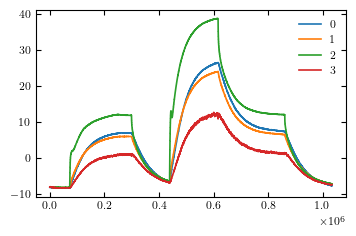

In [4]:
plt.plot(Theta_0, label="0")
plt.plot(Theta_1, label="1")
plt.plot(Theta_2, label="2")
plt.plot(Theta_3, label="3")

plt.legend()

In [6]:
# Parametri simulazione
L = 0.003 # (metri)
dt = 0.01
nt = np.size(Theta_0)
Tf = dt*nt

# Proprietà Al₂O₃
rho_Al2O3 = 3900        # kg/m³
cp_Al2O3 = 880          # J/(kg·K)
kappa_Al2O3 = 30        # W/(m·K) per Al₂O₃ tecnica
D = kappa_Al2O3 / (rho_Al2O3 * cp_Al2O3)
print(D)


wanted_r = 0.2
h = 12

keep_every = 1
dt = keep_every*dt
Theta_0 = Theta_0[1::keep_every]
nt = np.size(Theta_0)

from src.Heat1DCrankNicolson import Heat1DCrankNicolson

# Inizializza solver
solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

_, n_eff = solver.diffusion_time()

from src.TikhonovHandler import TikhonovHandler, reconstruction_error_plot
th = TikhonovHandler(solver)

8.741258741258741e-06

-----------------------------Solver info------------------------------

Diffusion time:                                               1.03e+00
dx:                                                           7.50e-04
dt:                                                           1.00e-02
nt:                                                            1032997
nx:                                                                  5
r:                                                            1.55e-01
h:                                                            1.20e+01


In [ ]:
g_target = Theta_0

f_reconstructed = th.regularize(g_target, lambda_reg=10, regularization_type_="closed", maxiter=5)

print(np.shape(g_target))
print(np.shape(f_reconstructed))


(1032998,)
(1032998,)


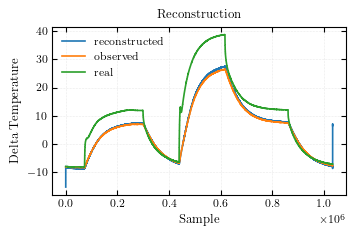

In [ ]:

plt.plot(f_reconstructed, label="reconstructed")
plt.plot(g_target, label="observed")
plt.plot(Theta_2[1::keep_every], label="real")
plt.xlabel("Sample")
plt.ylabel("Delta Temperature")
plt.title("Reconstruction")
plt.grid()
plt.legend()

plt.savefig(f"assets/tikhonov_learned/eltek_images/img2.pdf", dpi=150, bbox_inches='tight')